# T04 · EDA: idade, sexo, altura, peso e IMC

**Issue:** #4 · **Fase 1 · EDA** · **Dataset:** `data/raw/cardio_train.csv`

**Objetivo:** analisar as variáveis demográficas e corporais e encontrar os valores impossíveis de altura e peso. As faixas propostas no fim alimentam a **T08** (limpeza) e o IMC alimenta a **T10** (features).

> Aqui a análise é feita sobre os **dados brutos**, sem limpeza, justamente para encontrar os problemas.

In [1]:
import sys
from pathlib import Path

# Permite rodar o notebook fora do Docker (no Docker o PYTHONPATH já aponta para src/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from cardio.config import DATA_PATH, FIGURES_DIR, SEED
from cardio.data.loader import load_dataset

sns.set_theme(style="whitegrid")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
CLASSES = {0: "Sem doença", 1: "Com doença"}


def salvar(fig, nome):
    """Salva a figura em results/figures/ com o prefixo da tarefa."""
    fig.savefig(FIGURES_DIR / f"t04_{nome}.png", dpi=120, bbox_inches="tight")

In [2]:
df = load_dataset(DATA_PATH)

# Variáveis derivadas usadas nesta análise
df["age_years"] = df["age"] / 365.25
df["sexo"] = df["gender"].map({1: "Feminino", 2: "Masculino"})
df["bmi"] = df["weight"] / (df["height"] / 100) ** 2
df["classe"] = df["cardio"].map(CLASSES)

print(f"{len(df):,} pacientes".replace(",", "."))
df[["age_years", "height", "weight", "bmi"]].describe().round(1)

70.000 pacientes


,age_years,height,weight,bmi
count,70000.0,70000.0,70000.0,70000.0
mean,53.3,164.4,74.2,27.6
std,6.8,8.2,14.4,6.1
min,29.6,55.0,10.0,3.5
25%,48.4,159.0,65.0,23.9
50%,53.9,165.0,72.0,26.4
75%,58.4,170.0,82.0,30.2
max,64.9,250.0,200.0,298.7


## 1. Idade × doença cardiovascular

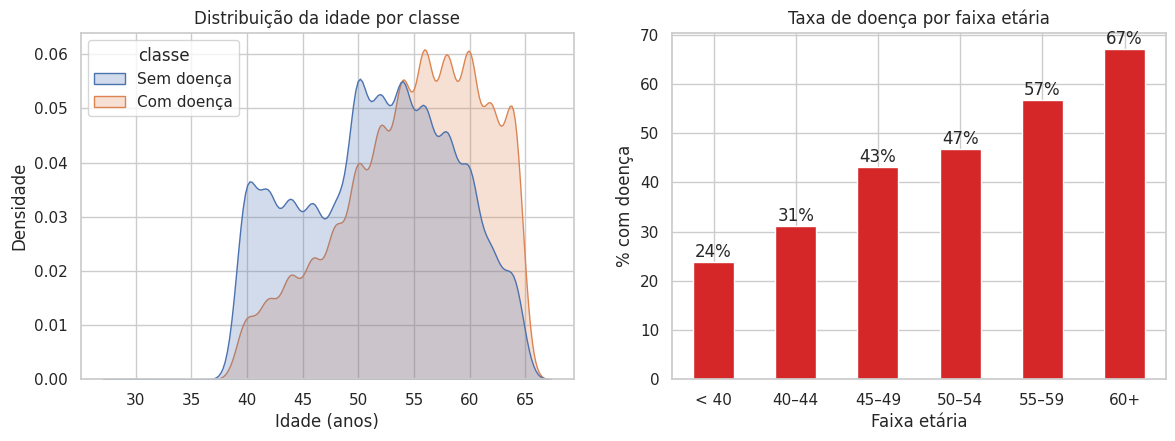

Correlação idade × cardio: 0.238


,count,mean,std,min,25%,50%,75%,max
classe,,,,,,,,
Com doença,34979.0,54.9,6.3,39.1,50.3,55.8,60.0,64.9
Sem doença,35021.0,51.7,6.8,29.6,46.1,52.0,57.2,64.8


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.kdeplot(data=df, x="age_years", hue="classe", fill=True, common_norm=False, ax=axes[0])
axes[0].set(title="Distribuição da idade por classe", xlabel="Idade (anos)", ylabel="Densidade")

df["faixa_etaria"] = pd.cut(df["age_years"], [0, 40, 45, 50, 55, 60, 70], right=False,
                            labels=["< 40", "40–44", "45–49", "50–54", "55–59", "60+"])
taxa_idade = df.groupby("faixa_etaria", observed=True)["cardio"].mean() * 100
taxa_idade.plot(kind="bar", ax=axes[1], color="tab:red")
axes[1].set(title="Taxa de doença por faixa etária", xlabel="Faixa etária", ylabel="% com doença")
axes[1].tick_params(axis="x", rotation=0)
for i, v in enumerate(taxa_idade):
    axes[1].text(i, v + 1, f"{v:.0f}%", ha="center")

salvar(fig, "idade_por_classe")
plt.show()

print("Correlação idade × cardio:", round(df["age_years"].corr(df["cardio"]), 3))
df.groupby("classe")["age_years"].describe().round(1)

**Interpretação:** sim, a doença aumenta com a idade. A correlação com o alvo é **0,24**, a maior entre as variáveis demográficas. A idade mediana é **52 anos** no grupo sem doença e **56 anos** no grupo com doença. A taxa de doença sobe de forma contínua, de **24%** abaixo dos 40 anos para **67%** a partir dos 60.

A idade vai de 29,6 a 64,9 anos, sem valores impossíveis. Ela vem em **dias** no CSV, então precisa ser convertida para anos.

## 2. Sexo

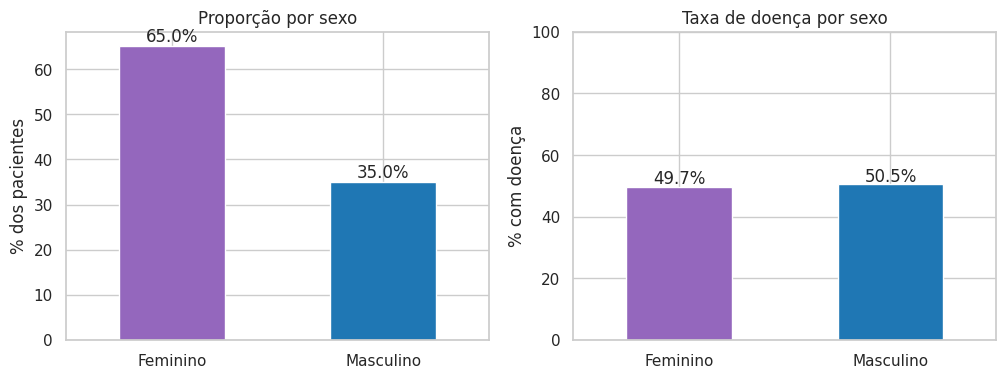

,height,weight
sexo,,
Feminino,161.4,72.6
Masculino,169.9,77.3


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

prop = df["sexo"].value_counts(normalize=True) * 100
prop.plot(kind="bar", ax=axes[0], color=["tab:purple", "tab:blue"])
axes[0].set(title="Proporção por sexo", xlabel="", ylabel="% dos pacientes")
axes[0].tick_params(axis="x", rotation=0)

taxa_sexo = df.groupby("sexo")["cardio"].mean() * 100
taxa_sexo.plot(kind="bar", ax=axes[1], color=["tab:purple", "tab:blue"])
axes[1].set(title="Taxa de doença por sexo", xlabel="", ylabel="% com doença", ylim=(0, 100))
axes[1].tick_params(axis="x", rotation=0)
for ax, serie in ((axes[0], prop), (axes[1], taxa_sexo)):
    for i, v in enumerate(serie):
        ax.text(i, v + 1, f"{v:.1f}%", ha="center")

salvar(fig, "sexo")
plt.show()

df.groupby("sexo")[["height", "weight"]].mean().round(1)

**Interpretação:** o dataset tem **65% de mulheres** e 35% de homens. A codificação é `gender = 1` para mulheres e `2` para homens: a altura média do grupo 1 é 161 cm e a do grupo 2 é 170 cm.

A taxa de doença é praticamente igual entre os sexos (**49,7%** nas mulheres e **50,5%** nos homens). Sozinho, o sexo diz pouco sobre a doença. Mesmo assim, o desequilíbrio da amostra precisa entrar na discussão de limitações (T34) e na análise por subgrupo (T26).

## 3. Altura e peso por classe

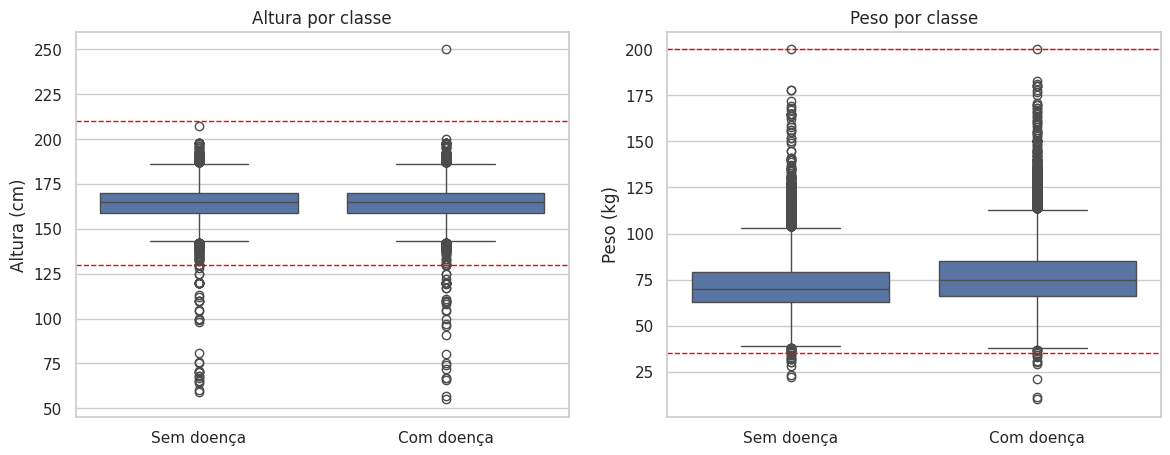

Correlação com cardio -> altura: -0.011 | peso: 0.182


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="classe", y="height", ax=axes[0])
axes[0].set(title="Altura por classe", xlabel="", ylabel="Altura (cm)")
sns.boxplot(data=df, x="classe", y="weight", ax=axes[1])
axes[1].set(title="Peso por classe", xlabel="", ylabel="Peso (kg)")
for ax, (lo, hi) in zip(axes, [(130, 210), (35, 200)]):
    ax.axhline(lo, color="red", ls="--", lw=1)
    ax.axhline(hi, color="red", ls="--", lw=1)
salvar(fig, "altura_peso_por_classe")
plt.show()

print("Correlação com cardio -> altura:", round(df["height"].corr(df["cardio"]), 3),
      "| peso:", round(df["weight"].corr(df["cardio"]), 3))

In [6]:
# Valores implausíveis
implausiveis = {
    "altura < 130 cm": (df["height"] < 130).sum(),
    "altura > 210 cm": (df["height"] > 210).sum(),
    "peso < 35 kg": (df["weight"] < 35).sum(),
    "peso > 200 kg": (df["weight"] > 200).sum(),
}
display(pd.Series(implausiveis, name="casos").to_frame())

# Exemplos: adultos com menos de 130 cm
df.loc[df["height"] < 130, ["age_years", "sexo", "height", "weight", "bmi"]].sort_values("height").head(8).round(1)

,casos
altura < 130 cm,92
altura > 210 cm,1
peso < 35 kg,20
peso > 200 kg,0


,age_years,sexo,height,weight,bmi
22723,64.0,Feminino,55,81.0,267.8
66643,51.6,Feminino,57,61.0,187.8
64115,50.4,Feminino,59,57.6,165.5
29157,52.3,Feminino,60,69.0,191.7
27603,57.4,Feminino,64,61.0,148.9
33607,54.0,Masculino,65,72.0,170.4
44490,52.3,Feminino,65,60.0,142.0
64454,58.4,Feminino,66,63.0,144.6


**Interpretação:** a altura praticamente não se relaciona com a doença (correlação **−0,01**; mediana de 165 cm nos dois grupos). O peso tem relação moderada (**0,18**), com mediana de 70 kg no grupo sem doença e **75 kg** no grupo com doença.

As linhas vermelhas marcam as faixas propostas. Fora delas há registros claramente errados, provavelmente de digitação. Exemplos: um adulto de **55 cm**, outro de 76 cm com 55 kg, e pesos de **10 kg**. São **92 casos** com altura abaixo de 130 cm, **1** acima de 210 cm e **20** com peso abaixo de 35 kg.

## 4. IMC

IMC < 15: 27 | IMC > 60: 66


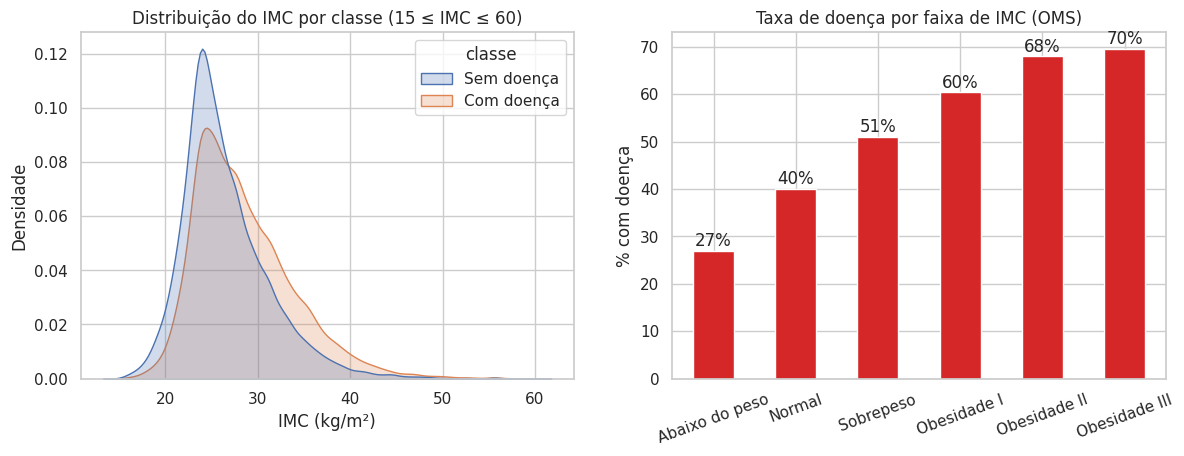

Correlação IMC × cardio (IMC válido): 0.193


,pacientes,taxa_doenca
imc_faixa,,
Abaixo do peso,623,27.0
Normal,25790,40.1
Sobrepeso,25086,51.0
Obesidade I,12212,60.4
Obesidade II,4376,68.0
Obesidade III,1820,69.6


In [7]:
df["imc_faixa"] = pd.cut(
    df["bmi"], [0, 18.5, 25, 30, 35, 40, float("inf")], right=False,
    labels=["Abaixo do peso", "Normal", "Sobrepeso", "Obesidade I", "Obesidade II", "Obesidade III"],
)
imc_valido = df["bmi"].between(15, 60)
print(f"IMC < 15: {(df['bmi'] < 15).sum()} | IMC > 60: {(df['bmi'] > 60).sum()}")

tabela_imc = (df[imc_valido].groupby("imc_faixa", observed=True)["cardio"]
              .agg(pacientes="size", taxa_doenca="mean"))
tabela_imc["taxa_doenca"] = (tabela_imc["taxa_doenca"] * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.kdeplot(data=df[imc_valido], x="bmi", hue="classe", fill=True, common_norm=False, ax=axes[0])
axes[0].set(title="Distribuição do IMC por classe (15 ≤ IMC ≤ 60)", xlabel="IMC (kg/m²)", ylabel="Densidade")
tabela_imc["taxa_doenca"].plot(kind="bar", ax=axes[1], color="tab:red")
axes[1].set(title="Taxa de doença por faixa de IMC (OMS)", xlabel="", ylabel="% com doença")
axes[1].tick_params(axis="x", rotation=20)
for i, v in enumerate(tabela_imc["taxa_doenca"]):
    axes[1].text(i, v + 1, f"{v:.0f}%", ha="center")
salvar(fig, "imc")
plt.show()

print("Correlação IMC × cardio (IMC válido):", round(df.loc[imc_valido, "bmi"].corr(df.loc[imc_valido, "cardio"]), 3))
tabela_imc

**Interpretação:** o IMC mostra uma relação clara e crescente com a doença. A taxa sobe de **27%** em quem está abaixo do peso para **40%** no peso normal, **51%** no sobrepeso e chega a **70%** na obesidade grau III.

A correlação com o alvo (**0,20**) é maior que a do peso sozinho, o que reforça o IMC como feature para a **T10**. O IMC também ajuda a pegar erros que passam nos limites de altura e peso separados: **27 casos** com IMC abaixo de 15 e **66** acima de 60, fisiologicamente improváveis para adultos.

## 5. Faixas plausíveis propostas (para a T08)

In [8]:
regras = [
    ("Altura", "height", 130, 210, "cm", "Adultos abaixo de 130 cm ou acima de 210 cm são raríssimos; os casos fora são erros de registro."),
    ("Peso", "weight", 35, 200, "kg", "Abaixo de 35 kg é incompatível com adultos nessas alturas; o máximo do dataset é 200 kg."),
    ("IMC", "bmi", 15, 60, "kg/m²", "IMC < 15 indica desnutrição extrema e > 60 é excepcional; pega combinações altura/peso inválidas."),
]
proposta = pd.DataFrame([
    {"Variável": nome, "Faixa plausível": f"{lo}–{hi} {un}",
     "Casos fora": int((~df[col].between(lo, hi)).sum()), "Justificativa": just}
    for nome, col, lo, hi, un, just in regras
])

dentro = df["height"].between(130, 210) & df["weight"].between(35, 200) & df["bmi"].between(15, 60)
print(f"Total removido aplicando as três regras: {(~dentro).sum()} linhas ({(~dentro).mean():.2%})")
pd.set_option("display.max_colwidth", None)
proposta

Total removido aplicando as três regras: 147 linhas (0.21%)


,Variável,Faixa plausível,Casos fora,Justificativa
0,Altura,130–210 cm,93,Adultos abaixo de 130 cm ou acima de 210 cm são raríssimos; os casos fora são erros de registro.
1,Peso,35–200 kg,20,Abaixo de 35 kg é incompatível com adultos nessas alturas; o máximo do dataset é 200 kg.
2,IMC,15–60 kg/m²,93,IMC < 15 indica desnutrição extrema e > 60 é excepcional; pega combinações altura/peso inválidas.


### Conclusões

- **Idade** é a variável demográfica mais associada à doença: a taxa vai de 24% (< 40 anos) a 67% (60+).
- **Sexo** quase não diferencia as classes, mas a amostra é **65% feminina**: isso é uma limitação a registrar.
- **Altura** não tem relação com a doença; **peso** tem relação moderada.
- **IMC** tem relação crescente e clara com a doença e deve virar feature (**T10**).
- **Proposta para a T08:** altura entre **130 e 210 cm**, peso entre **35 e 200 kg** e IMC entre **15 e 60**. Juntas, essas regras removem **147 linhas (0,21%)**, o que não afeta o tamanho da amostra.

As figuras foram salvas em `results/figures/` com o prefixo `t04_`.